In [ ]:
import pandas as pd

df = pd.read_csv("match_data.csv") 

C:\Users\Aun Abbas\AppData\Local\Temp\ipykernel_11572\1494593808.py:3: DtypeWarning: Columns (0: season) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("match_data.csv")  # use your correct file name


In [2]:
teams = df.groupby('match_id')['batting_team'].unique().reset_index()

teams[['team1', 'team2']] = pd.DataFrame(teams['batting_team'].tolist(), index=teams.index)

teams = teams.drop('batting_team', axis=1)

In [3]:
match_df = df[['match_id', 'season', 'venue']].drop_duplicates()

match_df = match_df.merge(teams, on='match_id')

In [4]:
runs = df.groupby(['match_id', 'batting_team'])['runs_off_bat'].sum().reset_index()

winner_df = runs.loc[runs.groupby('match_id')['runs_off_bat'].idxmax()]

winner_df = winner_df[['match_id', 'batting_team']].rename(columns={'batting_team': 'winner'})

match_df = match_df.merge(winner_df, on='match_id')

In [5]:
# Remove matches with missing values
match_df = match_df.dropna()

# Ensure everything is string BEFORE encoding
match_df['team1'] = match_df['team1'].astype(str)
match_df['team2'] = match_df['team2'].astype(str)
match_df['venue'] = match_df['venue'].astype(str)
match_df['winner'] = match_df['winner'].astype(str)

In [6]:
from sklearn.preprocessing import LabelEncoder

le_team = LabelEncoder()
le_venue = LabelEncoder()
le_winner = LabelEncoder()

# Fit on ALL teams (IMPORTANT)
all_teams = pd.concat([match_df['team1'], match_df['team2']])

le_team.fit(all_teams)

# Transform
match_df['team1'] = le_team.transform(match_df['team1'])
match_df['team2'] = le_team.transform(match_df['team2'])

match_df['venue'] = le_venue.fit_transform(match_df['venue'])
match_df['winner'] = le_winner.fit_transform(match_df['winner'])

In [7]:
X = match_df[['team1', 'team2', 'venue']]
y = match_df['winner']

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=5)

model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [10]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.5219512195121951


In [11]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.57      0.67        28
           1       0.00      0.00      0.00         9
           2       0.00      0.00      0.00        13
           3       0.29      0.67      0.40        15
           4       0.00      0.00      0.00         4
           5       0.00      0.00      0.00         5
           6       0.57      0.59      0.58        22
           7       0.00      0.00      0.00         1
           8       0.60      0.55      0.57        22
           9       0.75      1.00      0.86         3
          10       0.56      0.65      0.60        23
          11       0.17      0.50      0.25         2
          12       0.40      1.00      0.57         2
          13       0.56      0.59      0.57        17
          14       1.00      0.67      0.80         3
          15       0.00      0.00      0.00         1
          16       0.48      0.76      0.59        17
          17       0.56    

c:\MLprojects\IPL(Decision Trees)\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\MLprojects\IPL(Decision Trees)\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\MLprojects\IPL(Decision Trees)\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[16  0  0  2  0  0  1  0  1  0  1  0  0  0  0  0  2  5]
 [ 0  0  0  6  0  0  1  0  1  0  1  0  0  0  0  0  0  0]
 [ 1  0  0  5  0  0  0  0  1  1  0  0  1  2  0  0  2  0]
 [ 0  0  0 10  0  0  1  0  1  0  1  1  0  1  0  0  0  0]
 [ 0  0  0  2  0  0  0  0  0  0  1  0  0  0  0  0  1  0]
 [ 0  0  0  2  0  0  0  0  0  0  0  0  1  1  0  0  0  1]
 [ 0  0  0  1  0  0 13  0  0  0  2  1  0  1  0  0  4  0]
 [ 0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  1  0  0  2  0 12  0  2  1  0  2  0  0  0  2]
 [ 0  0  0  0  0  0  0  0  0  3  0  0  0  0  0  0  0  0]
 [ 2  0  0  1  0  0  1  0  0  0 15  1  0  0  0  0  3  0]
 [ 0  0  0  0  0  0  1  0  0  0  0  1  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  2  0  0  0  0  0]
 [ 1  0  0  1  0  0  1  0  1  0  1  1  0 10  0  0  1  0]
 [ 0  0  0  1  0  0  0  0  0  0  0  0  0  0  2  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  1  0  0  0  0  1  0  2  0  0  0  0  0 13  0]
 [ 0  0  0  2  0  0  1  0  2  0

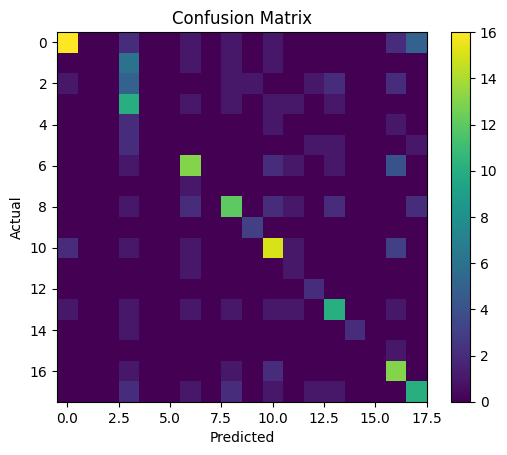

In [15]:
import matplotlib.pyplot as plt

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

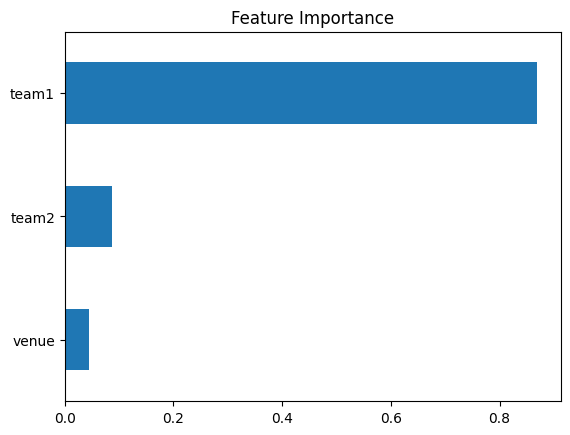

In [16]:
import pandas as pd

feature_importance = pd.Series(model.feature_importances_, index=X.columns)

feature_importance.sort_values().plot(kind='barh')
plt.title("Feature Importance")
plt.show()

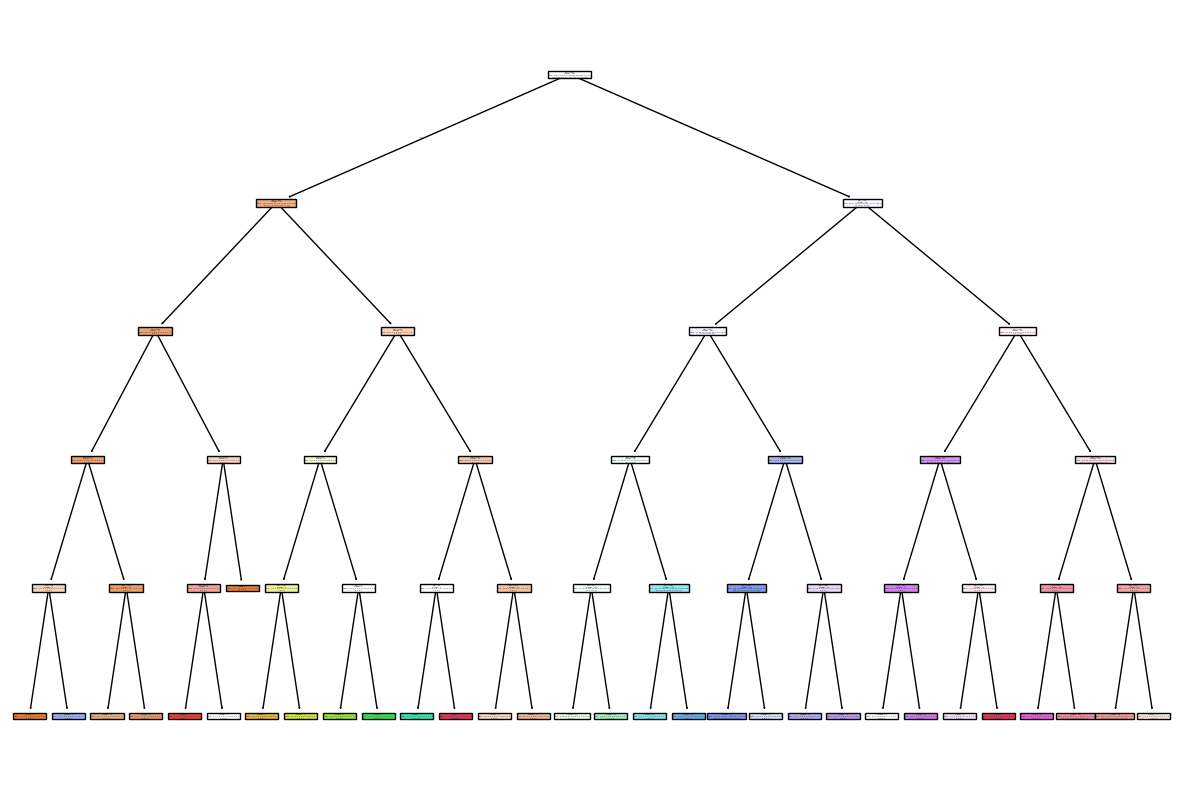

In [17]:
from sklearn.tree import plot_tree

plt.figure(figsize=(15,10))
plot_tree(model, feature_names=X.columns, filled=True)
plt.show()